# Visualizing numerical integration: step size, method order, and Runge–Kutta stages

This notebook shows how a numerical ODE integrator's accuracy depends on **step size**
and **method order**, and — the main event — *why* higher-order Runge–Kutta methods are
more accurate: within a single step they take several **minor-step** derivative samples
(the *stages*) and combine them into one far more accurate **major-step** estimate.

All data comes from the C++ program [`src/visualize_integration.cpp`](src/visualize_integration.cpp),
which drives the project's own integrators ([`include/integrators.hpp`](include/integrators.hpp))
on the canonical golf-ball v² drag model. The stage values it logs are asserted equal to the
real `*_step()` output, so what we plot is exactly what the integrators compute.

**Test problem:** a golf ball launched at v₀ = 100 m/s, 45°, quadratic air drag (k/m = 0.0057 1/m).
The "truth" in every comparison is an RK8 reference at Δt = 10⁻⁴ s.

See the final cell to regenerate the CSVs.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("viz_data")
meta     = pd.read_csv(DATA / "meta.csv").set_index("key")["value"]
traj     = pd.read_csv(DATA / "trajectories.csv")
errt     = pd.read_csv(DATA / "error_vs_time.csv")
conv     = pd.read_csv(DATA / "convergence.csv")
sstages  = pd.read_csv(DATA / "scalar_stages.csv")
ssummary = pd.read_csv(DATA / "scalar_summary.csv").set_index("method")
struth   = pd.read_csv(DATA / "scalar_truth.csv")

# one color + draw order per integrator, used throughout
COLOR = {"Euler": "#d62728", "Heun": "#ff7f0e", "RK4": "#1f77b4",
         "RK45": "#2ca02c", "RK8": "#9467bd"}
ORDER = ["Euler", "Heun", "RK4", "RK45", "RK8"]
plt.rcParams["figure.dpi"] = 110

print(f"model = {meta['model']}")
print(f"v0 = {meta['v0']} m/s   launch = {meta['launch_deg']}°   "
      f"k/m = {meta['k_over_m']} 1/m   g = {meta['g']} m/s²")
print(f"reference = {meta['ref_integrator']} at dt = {meta['ref_dt']} s")

model = v_squared_drag
v0 = 60 m/s   launch = 60°   k/m = 0.0025 1/m   g = 9.81 m/s²
reference = RK8 at dt = 0.0001 s


## 1 · Same method, smaller steps

The simplest knob is the step size Δt. Below, the **Euler** method integrates the same
trajectory at progressively smaller Δt. Coarse steps cut the curved path with long straight
chords and land far from the truth; each halving of Δt roughly halves the error — Euler is a
*first-order* method.

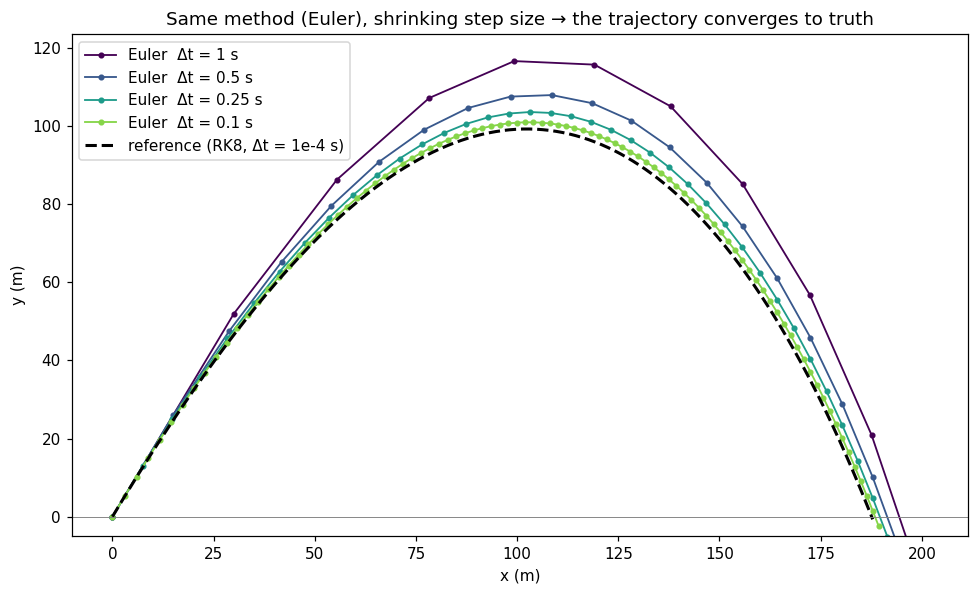

In [11]:
ref = traj[traj.study == "reference"].sort_values("t")
ss  = traj[traj.study == "stepsize"]

fig, ax = plt.subplots(figsize=(9, 5.5))
dts = sorted(ss.dt.unique(), reverse=True)
shades = plt.cm.viridis(np.linspace(0.0, 0.82, len(dts)))
for shade, dt in zip(shades, dts):
    d = ss[ss.dt == dt].sort_values("step")
    ax.plot(d.x, d.y, "-o", ms=3, lw=1.2, color=shade, label=f"Euler  Δt = {dt:g} s")
ax.plot(ref.x, ref.y, "k--", lw=2.0, label="reference (RK8, Δt = 1e-4 s)")
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("Same method (Euler), shrinking step size → the trajectory converges to truth")
ax.set_ylim(bottom=-5)
ax.legend()
plt.tight_layout(); plt.show()

## 2 · Different methods, same step size

Now hold the step size fixed and swap the integrator. On the full trajectory (left), Euler
(1st order) overshoots and Heun (2nd order) undershoots, while RK4 / RK45 / RK8 sit on the
reference. Zooming into the landing region (right) shows the spread: Euler and Heun miss by
metres, but the three high-order methods all land within ~0.1 m of the truth — and of *each
other*. On the path they are genuinely indistinguishable.

To see how the high-order methods actually differ you have to look at **error on a log scale**.
The error-vs-time plot below (run at a finer Δt over the whole flight) separates all five methods
into distinct bands that grow as the flight proceeds.

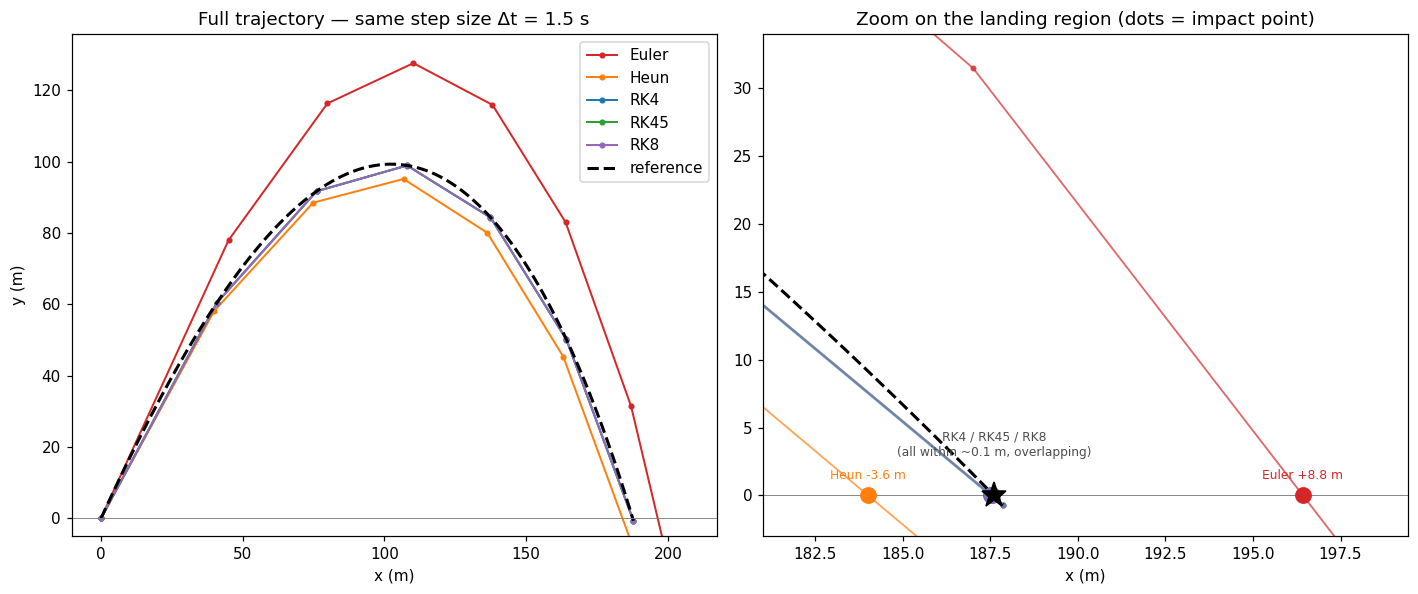

In [12]:
ist = traj[traj.study == "integrator"]
dt_cmp = ist.dt.iloc[0]

def land_x(d):  # interpolate the ground-impact x from the last two points
    d = d.sort_values("step"); a, b = d.iloc[-2], d.iloc[-1]
    return a.x + (-a.y) * (b.x - a.x) / (b.y - a.y)
lands = {name: land_x(ist[ist.integrator == name]) for name in ORDER}
ref_land = land_x(ref)

fig, (ax, axz) = plt.subplots(1, 2, figsize=(13, 5.5))
for name in ORDER:
    d = ist[ist.integrator == name].sort_values("step")
    ax.plot(d.x, d.y, "-o", ms=3, lw=1.3, color=COLOR[name], label=name)
    axz.plot(d.x, d.y, "-o", ms=3, lw=1.2, color=COLOR[name], alpha=0.7)
for a in (ax, axz):
    a.plot(ref.x, ref.y, "k--", lw=2.0, label="reference")
    a.axhline(0, color="gray", lw=0.6)
    a.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"Full trajectory — same step size Δt = {dt_cmp:g} s")
ax.set_ylim(bottom=-5); ax.legend(loc="upper right")

# zoom on the landing region: where does each method touch down vs the truth?
for name in ORDER:
    axz.plot(lands[name], 0.0, "o", color=COLOR[name], ms=10, zorder=5)
axz.plot(ref_land, 0.0, "k*", ms=17, zorder=6)
lo = min(min(lands.values()), ref_land); hi = max(max(lands.values()), ref_land)
axz.set_xlim(lo - 3, hi + 3); axz.set_ylim(-3, 34)
axz.set_title("Zoom on the landing region (dots = impact point)")
for name in ("Euler", "Heun"):
    axz.annotate(f"{name} {lands[name] - ref_land:+.1f} m", (lands[name], 0),
                 textcoords="offset points", xytext=(0, 11), ha="center",
                 color=COLOR[name], fontsize=8)
axz.annotate("RK4 / RK45 / RK8\n(all within ~0.1 m, overlapping)", (ref_land, 0),
             textcoords="offset points", xytext=(0, 26), ha="center", fontsize=8, color="0.3")
plt.tight_layout(); plt.show()

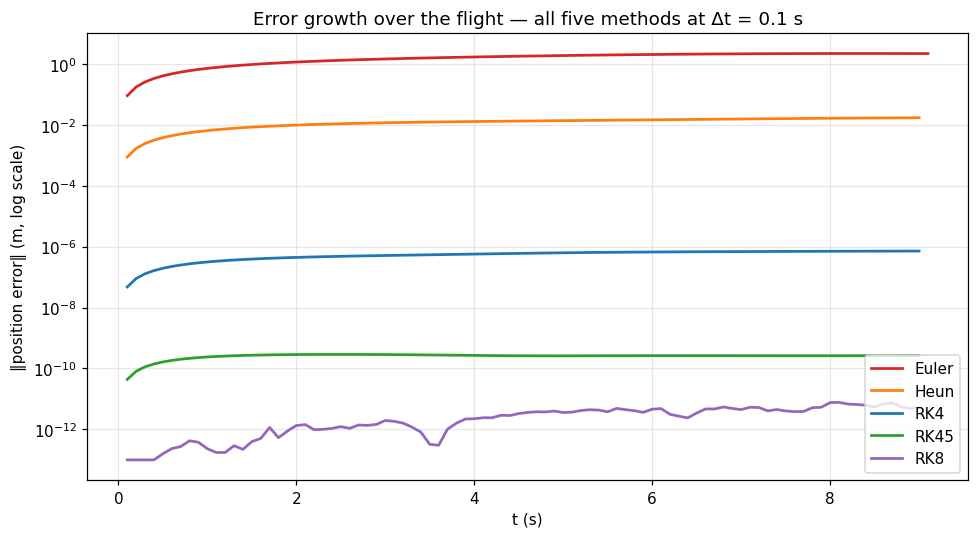

In [13]:
dt_e = errt.dt.iloc[0]
fig, ax = plt.subplots(figsize=(9, 5))
for name in ORDER:
    d = errt[(errt.integrator == name) & (errt.t > 0)]  # skip the zero-error launch point
    ax.semilogy(d.t, d.abs_error.clip(lower=1e-13), color=COLOR[name], lw=1.8, label=name)
ax.set_xlabel("t (s)"); ax.set_ylabel("‖position error‖ (m, log scale)")
ax.set_title(f"Error growth over the flight — all five methods at Δt = {dt_e:g} s")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 3 · Order of accuracy — and do the curves ever cross?

Plotting the global error at t = 5 s against Δt on log–log axes turns each method into a line
whose **slope, in the asymptotic (small-Δt) regime, equals its order**: Euler ≈ 1, Heun ≈ 2,
RK4 ≈ 4, RK45 ≈ 5 (it *super-converges* to ≈ 7 here — higher-order error terms partly cancel),
RK8 ≈ 8. (All methods share one common Δt range, and this study uses a faster shot than the
plots above so the high-order methods stay above the round-off floor long enough to show a slope.)

**Do the curves intersect if you extend them?** Two distinct things happen:

- **At coarse Δt (left):** the methods are not yet in their asymptotic regime, and "order" no
  longer ranks them — RK4 and RK45 actually **cross** near Δt ≈ 1 (the order-5 method is briefly
  *worse* than the order-4 one). Order is a small-Δt statement.
- **At fine Δt (right):** each higher order is uniformly better, until the curves flatten and
  **bunch together at the round-off floor** (~10⁻¹¹–10⁻¹² m, set by double-precision arithmetic).
  Below the floor, more order buys nothing.

So the only genuine crossings are the coarse-Δt scramble; the only "merging" is at the floor. In
between, the ranking by order holds and the lines stay nicely separated.

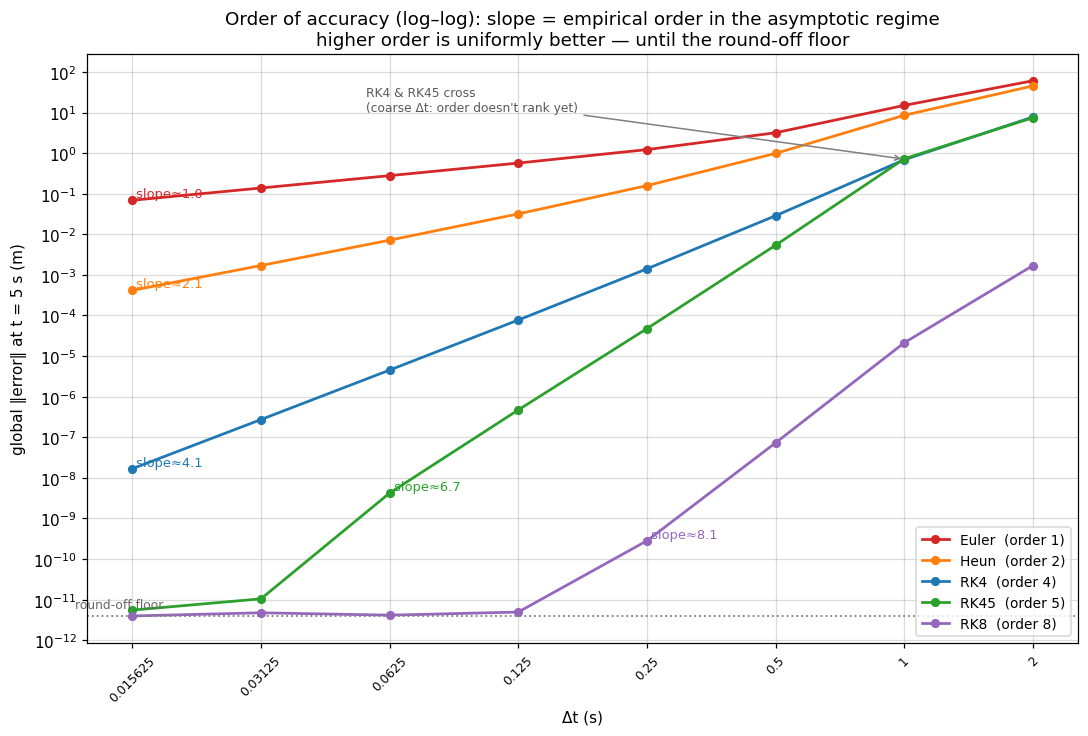

In [14]:
from matplotlib.ticker import LogLocator

# Fit the slope only over each method's asymptotic window (coarse Δt is
# sub-asymptotic; very fine Δt is round-off-floor-limited).
FITW = {"Euler": (0.0, 0.2), "Heun": (0.0, 0.2), "RK4": (0.0, 0.2),
        "RK45": (0.05, 0.6), "RK8": (0.2, 1.1)}

fig, ax = plt.subplots(figsize=(10, 6.8))
for name in ORDER:
    d = conv[conv.integrator == name].sort_values("dt")
    order = int(d.theoretical_order.iloc[0])
    ax.loglog(d.dt, d.error, "o-", color=COLOR[name], lw=1.8, ms=5,
              label=f"{name}  (order {order})")
    lo, hi = FITW[name]
    w = d[(d.dt > lo) & (d.dt <= hi)]
    if len(w) >= 2:
        s = np.polyfit(np.log(w.dt), np.log(w.error), 1)[0]
        ax.annotate(f" slope≈{s:.1f}", (w.dt.iloc[0], w.error.iloc[0]),
                    fontsize=8.5, color=COLOR[name], va="bottom")

# round-off floor and the coarse-Δt crossing of the order-4 / order-5 curves
floor = conv[conv.integrator == "RK8"].error.min()
ax.axhline(floor, color="0.5", ls=":", lw=1.2)
ax.text(0.0115, floor * 1.6, "round-off floor", fontsize=8, color="0.4")
ax.annotate("RK4 & RK45 cross\n(coarse Δt: order doesn't rank yet)",
            xy=(1.0, 0.71), xytext=(0.055, 11), fontsize=8, color="0.35",
            arrowprops=dict(arrowstyle="->", color="0.5", lw=1.0))

# labelled ticks + grid so magnitudes read off directly (no counting minor ticks)
dts = sorted(conv.dt.unique())
ax.set_xticks(dts); ax.set_xticklabels([f"{d:g}" for d in dts], rotation=45, fontsize=8)
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=30))
ax.grid(True, which="major", alpha=0.45)
ax.grid(True, which="minor", axis="y", alpha=0.15)
ax.set_xlabel("Δt (s)"); ax.set_ylabel("global ‖error‖ at t = 5 s (m)")
ax.set_title("Order of accuracy (log–log): slope = empirical order in the asymptotic regime\n"
             "higher order is uniformly better — until the round-off floor")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## 4 · Inside one step: how the stage slopes build a more accurate "major-step" slope

To see *why* a higher-order method beats a single Euler step at the **same Δt**, watch one step on
a sample function whose answer we know exactly: the ODE  y′ = y,  starting at y₀ = 1, whose true
solution is  y(t) = eᵗ.

A single **Euler** step commits to one number — the slope at the start, k₁ = 1 — and follows it
straight across the whole step. But the curve steepens as it rises, so that starting slope is too
shallow and Euler lands short (at 2.00 instead of e ≈ 2.718).

**RK4** instead evaluates the derivative four times within the step — at the start (k₁, a *major*
point), twice at the midpoint (k₂, k₃, the *minor* point), and once at the end (k₄, a *major*
point) — then uses the weighted average (k₁ + 2k₂ + 2k₃ + k₄)/6 as the slope it actually takes:
the **major-step derivative**. Because that blend samples the steeper interior slopes, it nearly
equals the true average rate of change across the step, so the step lands almost exactly on the curve.

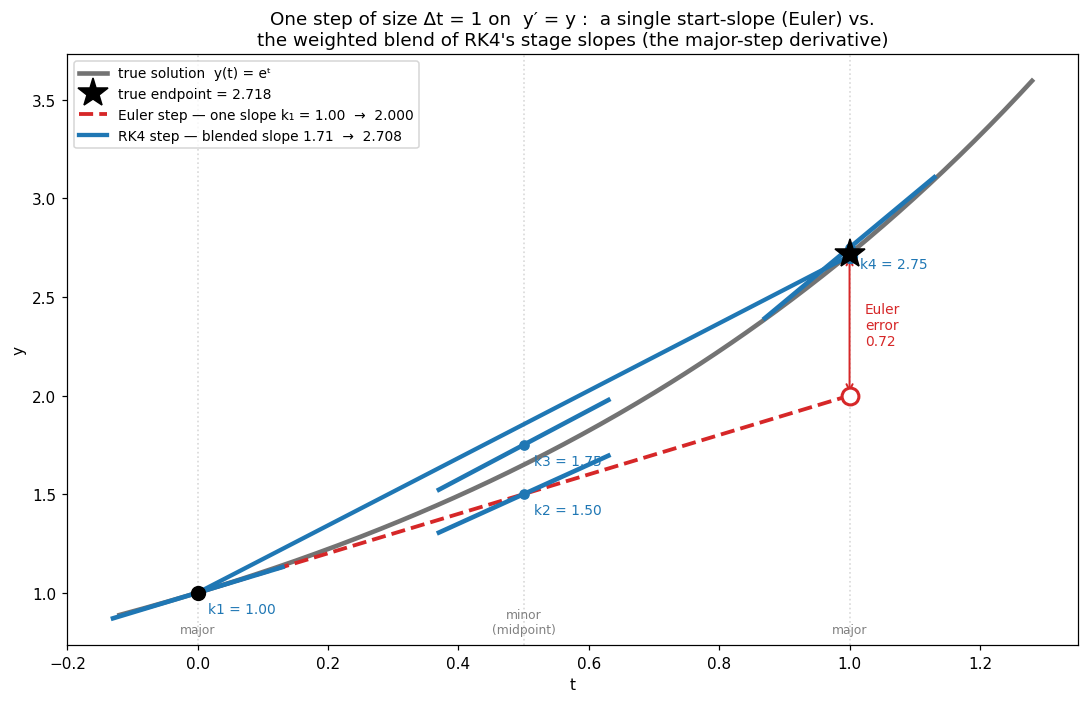

In [15]:
sm = ssummary
h  = float(sm.loc["RK4", "h"]); t0 = float(sm.loc["RK4", "t0"]); y0 = float(sm.loc["RK4", "y0"])
t1 = t0 + h
ytrue = float(sm.loc["RK4", "y_true"])
yE, kE = float(sm.loc["Euler", "y1"]), float(sm.loc["Euler", "k_eff"])
yR, kR = float(sm.loc["RK4", "y1"]),   float(sm.loc["RK4", "k_eff"])

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(struth.t, struth.y, color="0.45", lw=3, zorder=1, label="true solution  y(t) = eᵗ")

# step boundaries (major points) and the midpoint (minor point), labelled along the bottom
trans = ax.get_xaxis_transform()  # x in data coords, y in axes fraction
for tv, lab in [(t0, "major"), (t0 + h / 2, "minor\n(midpoint)"), (t1, "major")]:
    ax.axvline(tv, color="0.85", ls=":", lw=1.1, zorder=0)
    ax.text(tv, 0.015, lab, transform=trans, ha="center", va="bottom", fontsize=8, color="0.5")

# RK4 stage slopes as short tangent segments at the points where they were sampled
rk = sstages[sstages.method == "RK4"].sort_values("stage")
seg = 0.13 * h
for _, s in rk.iterrows():
    t, y, k = s.eval_t, s.eval_y, s.slope
    ax.plot([t - seg, t + seg], [y - seg * k, y + seg * k], "-", color="#1f77b4", lw=3, zorder=5)
    ax.plot(t, y, "o", color="#1f77b4", ms=6, zorder=6)
    ax.annotate(f"k{int(s.stage) + 1} = {k:.2f}", (t, y), textcoords="offset points",
                xytext=(7, -13), fontsize=9, color="#1f77b4")

ax.plot(t0, y0, "ko", ms=9, zorder=7)
ax.plot(t1, ytrue, "*", color="k", ms=20, zorder=8, label=f"true endpoint = {ytrue:.3f}")

# the two steps: Euler (one start slope) vs RK4 (the blended slope)
ax.plot([t0, t1], [y0, yE], "--", color="#d62728", lw=2.5, zorder=4,
        label=f"Euler step — one slope k₁ = {kE:.2f}  →  {yE:.3f}")
ax.plot(t1, yE, "o", mfc="white", mec="#d62728", mew=2, ms=11, zorder=7)
ax.plot([t0, t1], [y0, yR], "-", color="#1f77b4", lw=2.8, zorder=4,
        label=f"RK4 step — blended slope {kR:.2f}  →  {yR:.3f}")
ax.plot(t1, yR, "o", color="#1f77b4", ms=9, zorder=7)

ax.annotate("", xy=(t1, ytrue), xytext=(t1, yE),
            arrowprops=dict(arrowstyle="<->", color="#d62728", lw=1.3))
ax.annotate(f"Euler\nerror\n{abs(ytrue - yE):.2f}", (t1, (yE + ytrue) / 2),
            textcoords="offset points", xytext=(10, 0), color="#d62728", fontsize=9, va="center")

ax.set_xlabel("t"); ax.set_ylabel("y")
ax.set_title(f"One step of size Δt = {h:g} on  y′ = y :  a single start-slope (Euler) vs.\n"
             f"the weighted blend of RK4's stage slopes (the major-step derivative)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

### The blend vs. the exact answer

The exact average slope over the step is the secant slope  (y(t₀+Δt) − y₀)/Δt = (e − 1)/1 ≈ 1.718.
RK4's weighted blend of its four stage slopes comes out to ≈ 1.708 — within 0.6% — while Euler's
lone start slope of 1.000 is 42% too shallow. *That* gap is the accuracy difference. The bar chart
shows each stage slope and its weight, and how the blend lands almost exactly on the exact secant
slope (dashed), far above Euler's single slope (dotted).

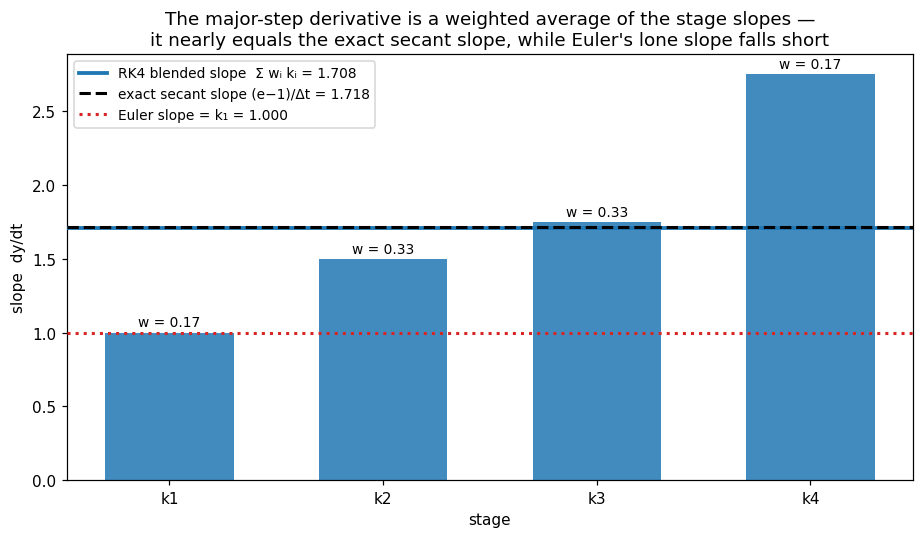

In [16]:
rk = sstages[sstages.method == "RK4"].sort_values("stage")
keff   = float(ssummary.loc["RK4", "k_eff"])
secant = float(ssummary.loc["RK4", "secant_slope"])
k1     = float(rk.slope.iloc[0])

fig, ax = plt.subplots(figsize=(8.5, 5))
xpos = list(range(len(rk)))
ax.bar(xpos, rk.slope, width=0.6, color="#1f77b4", alpha=0.85, zorder=2)
for x, (_, s) in zip(xpos, rk.iterrows()):
    ax.annotate(f"w = {s.weight:.2f}", (x, s.slope), textcoords="offset points",
                xytext=(0, 4), ha="center", fontsize=9)
ax.axhline(keff,   color="#1f77b4", lw=2.5,           label=f"RK4 blended slope  Σ wᵢ kᵢ = {keff:.3f}", zorder=3)
ax.axhline(secant, color="k",       lw=2.0, ls="--",  label=f"exact secant slope (e−1)/Δt = {secant:.3f}", zorder=3)
ax.axhline(k1,     color="#d62728", lw=2.0, ls=":",   label=f"Euler slope = k₁ = {k1:.3f}", zorder=3)
ax.set_xticks(xpos); ax.set_xticklabels([f"k{int(s) + 1}" for s in rk.stage])
ax.set_xlabel("stage"); ax.set_ylabel("slope  dy/dt")
ax.set_title("The major-step derivative is a weighted average of the stage slopes —\n"
             "it nearly equals the exact secant slope, while Euler's lone slope falls short")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

In [17]:
rk = sstages[sstages.method == "RK4"].sort_values("stage")
keff = float((rk.weight * rk.slope).sum())
print("RK4 step for  y' = y ,  y0 = 1 ,  Δt = 1     (true y(1) = e = 2.71828)\n")
print("  stage   eval_t   slope kᵢ   weight wᵢ")
for _, s in rk.iterrows():
    print(f"   k{int(s.stage) + 1}      {s.eval_t:.2f}     {s.slope:7.4f}     {s.weight:.4f}")
print(f"\n  blended major-step slope  Σ wᵢ kᵢ = {keff:.4f}")
print(f"  exact secant slope (e−1)/Δt       = {float(ssummary.loc['RK4', 'secant_slope']):.4f}")
print(f"  Euler slope (k1 only)             = {float(rk.slope.iloc[0]):.4f}\n")
print(f"  RK4 endpoint  = y0 + Δt·{keff:.4f}  = {float(ssummary.loc['RK4', 'y1']):.5f}")
print(f"  Euler endpoint                     = {float(ssummary.loc['Euler', 'y1']):.5f}")
print(f"  true endpoint = e                  = {float(ssummary.loc['RK4', 'y_true']):.5f}")

RK4 step for  y' = y ,  y0 = 1 ,  Δt = 1     (true y(1) = e = 2.71828)

  stage   eval_t   slope kᵢ   weight wᵢ
   k1      0.00      1.0000     0.1667
   k2      0.50      1.5000     0.3333
   k3      0.50      1.7500     0.3333
   k4      1.00      2.7500     0.1667

  blended major-step slope  Σ wᵢ kᵢ = 1.7083
  exact secant slope (e−1)/Δt       = 1.7183
  Euler slope (k1 only)             = 1.0000

  RK4 endpoint  = y0 + Δt·1.7083  = 2.70833
  Euler endpoint                     = 2.00000
  true endpoint = e                  = 2.71828


### More stage samples → less error, at the same Δt

Holding Δt = 1 fixed, the one-step error collapses as we add stages: Euler (1 sample) → Heun (2)
→ RK4 (4). That is the whole payoff of higher order — a few extra derivative evaluations per step,
placed and weighted well, buy orders of magnitude in accuracy.

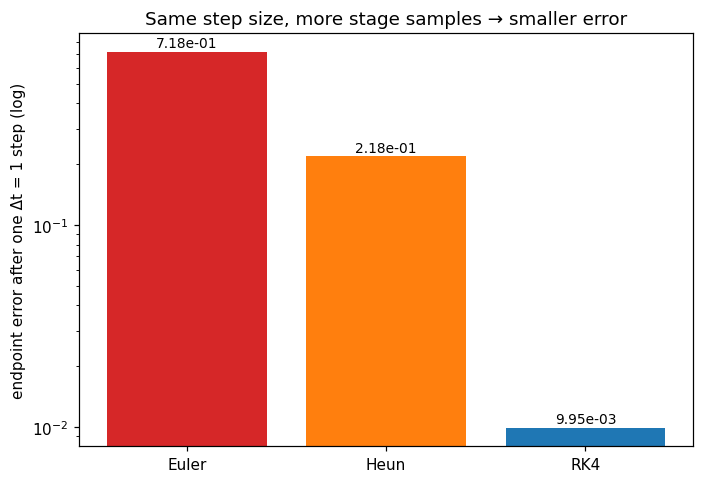

In [18]:
methods = ["Euler", "Heun", "RK4"]
errs = [float(ssummary.loc[m, "error"]) for m in methods]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(methods, errs, color=[COLOR[m] for m in methods])
ax.set_yscale("log")
ax.set_ylabel("endpoint error after one Δt = 1 step (log)")
ax.set_title("Same step size, more stage samples → smaller error")
for m, e in zip(methods, errs):
    ax.annotate(f"{e:.2e}", (m, e), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## Summary & regeneration

- **Step size** — smaller Δt → smaller error; the *rate* of improvement is set by the method's order.
- **Method order** — at a fixed Δt, a higher-order method is more accurate by orders of magnitude.
- **Why** — higher-order methods sample the derivative at several interior points within the step
  and average them into a *major step* that follows the true solution's curvature, instead of
  committing to a single starting slope.

**Regenerate the CSVs** (from the repo root):

```bash
cmake -S . -B build && cmake --build build --target visualize_integration -j
mkdir -p viz_data && ./build/visualize_integration viz_data
```

Then re-run this notebook (kernel: `.test-env2`).